# 02 · Feature engineering, model training & experiment tracking
The production training entry point is `python -m heart.train`. This notebook inspects the results stored in MLflow.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path[:0] = [str(ROOT / "src"), str(ROOT)]
import os; os.chdir(ROOT)

In [2]:
from heart.features import build_preprocessor, HeartFeatureBuilder
from heart.data import load_clean, split_xy
X, y = split_xy(load_clean())
HeartFeatureBuilder().transform(X).head()

,age,trestbps,chol,thalach,oldpeak,cp,restecg,slope,ca,thal,sex,fbs,exang,hr_reserve_pct,chol_per_age,st_risk_flag
0,63.0,145.0,233.0,150.0,2.3,1.0,2.0,3.0,0.0,6.0,1.0,1.0,0.0,0.955414,3.698413,1.0
1,67.0,160.0,286.0,108.0,1.5,4.0,2.0,2.0,3.0,3.0,1.0,0.0,1.0,0.705882,4.268657,1.0
2,67.0,120.0,229.0,129.0,2.6,4.0,2.0,2.0,2.0,7.0,1.0,0.0,1.0,0.843137,3.417910,1.0
3,37.0,130.0,250.0,187.0,3.5,3.0,0.0,3.0,0.0,3.0,1.0,0.0,0.0,1.021858,6.756757,1.0
4,41.0,130.0,204.0,172.0,1.4,2.0,2.0,1.0,0.0,3.0,0.0,0.0,0.0,0.960894,4.975610,0.0


In [3]:
pre = build_preprocessor().fit(X)
print(pre)
print(len(pre.named_steps['preprocess'].get_feature_names_out()), "model features:")
list(pre.named_steps['preprocess'].get_feature_names_out())

Pipeline(steps=[('features', HeartFeatureBuilder()),
                ('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalach', 'oldpeak',
                                                   'hr_reserve_pct',
                                                   'chol_per_age',
                                                   'st_risk_flag']),
                                                 ('cat',
                                                  Pipeline(steps=[('impute',
                          

['age',
 'trestbps',
 'chol',
 'thalach',
 'oldpeak',
 'hr_reserve_pct',
 'chol_per_age',
 'st_risk_flag',
 'cp_1.0',
 'cp_2.0',
 'cp_3.0',
 'cp_4.0',
 'restecg_0.0',
 'restecg_1.0',
 'restecg_2.0',
 'slope_1.0',
 'slope_2.0',
 'slope_3.0',
 'ca_0.0',
 'ca_1.0',
 'ca_2.0',
 'ca_3.0',
 'thal_3.0',
 'thal_6.0',
 'thal_7.0',
 'sex',
 'fbs',
 'exang']

## Train all candidates (same code path as `python -m heart.train`)

In [4]:
from heart import train
meta = train.run(quick=False)   # quick=True for a fast smoke run
meta["model_name"], meta["metrics"]["cv_roc_auc_mean"]

/home/claude/venv/lib/python3.11/site-packages/numpy/ma/core.py:2820: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


            model  cv_accuracy_mean  cv_accuracy_std  cv_precision_mean  cv_precision_std  cv_recall_mean  cv_recall_std  cv_f1_mean  cv_f1_std  cv_roc_auc_mean  cv_roc_auc_std  test_accuracy  test_precision  test_recall  test_f1  test_roc_auc
  logreg_baseline            0.8471           0.0100             0.8768            0.0542          0.7834         0.0459      0.8245     0.0069           0.9045          0.0145         0.8852          0.8387       0.9286   0.8814        0.9686
           logreg            0.8388           0.0161             0.8696            0.0604          0.7739         0.0775      0.8134     0.0257           0.9052          0.0132         0.8852          0.8387       0.9286   0.8814        0.9697
    random_forest            0.8141           0.0287             0.8193            0.0259          0.7648         0.0895      0.7877     0.0468           0.8945          0.0242         0.8852          0.8387       0.9286   0.8814        0.9610
gradient_boosting       

Registered model 'heart-disease-classifier' already exists. Creating a new version of this model...
Created version '2' of model 'heart-disease-classifier'.


('logreg', 0.9052)

## MLflow runs

In [5]:
import mlflow
from heart.config import MLFLOW_TRACKING_URI, MLFLOW_EXPERIMENT
mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
runs = mlflow.search_runs(experiment_names=[MLFLOW_EXPERIMENT])
cols = ["tags.mlflow.runName","metrics.cv_roc_auc_mean","metrics.cv_accuracy_mean","metrics.cv_recall_mean","metrics.test_roc_auc","start_time"]
runs[[c for c in cols if c in runs]].dropna(subset=["metrics.cv_roc_auc_mean"]).sort_values("start_time", ascending=False).head(12)

,tags.mlflow.runName,metrics.cv_roc_auc_mean,metrics.cv_accuracy_mean,metrics.cv_recall_mean,metrics.test_roc_auc,start_time
0,gradient_boosting,0.881431,0.813861,0.773913,0.957792,2026-10-08 17:44:13.173000+00:00
1,random_forest,0.894476,0.814116,0.764822,0.961039,2026-10-08 17:43:24.607000+00:00
2,logreg,0.905233,0.838776,0.773913,0.969697,2026-10-08 17:43:20.160000+00:00
3,logreg_baseline,0.904535,0.847109,0.783399,0.968615,2026-10-08 17:43:14.964000+00:00
5,gradient_boosting,0.881431,0.813861,0.773913,0.957792,2026-10-08 17:39:15.686000+00:00
6,random_forest,0.894476,0.814116,0.764822,0.961039,2026-10-08 17:38:27.774000+00:00
7,logreg,0.905233,0.838776,0.773913,0.969697,2026-10-08 17:38:23.636000+00:00
8,logreg_baseline,0.904535,0.847109,0.783399,0.968615,2026-10-08 17:38:18.402000+00:00


In [6]:
import pandas as pd
pd.read_csv("reports/model_comparison.csv")

,model,cv_accuracy_mean,cv_accuracy_std,cv_precision_mean,cv_precision_std,cv_recall_mean,cv_recall_std,cv_f1_mean,cv_f1_std,cv_roc_auc_mean,cv_roc_auc_std,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
0,logreg_baseline,0.8471,0.0100,0.8768,0.0542,0.7834,0.0459,0.8245,0.0069,0.9045,0.0145,0.8852,0.8387,0.9286,0.8814,0.9686
1,logreg,0.8388,0.0161,0.8696,0.0604,0.7739,0.0775,0.8134,0.0257,0.9052,0.0132,0.8852,0.8387,0.9286,0.8814,0.9697
2,random_forest,0.8141,0.0287,0.8193,0.0259,0.7648,0.0895,0.7877,0.0468,0.8945,0.0242,0.8852,0.8387,0.9286,0.8814,0.9610
3,gradient_boosting,0.8139,0.0275,0.8215,0.0714,0.7739,0.0660,0.7920,0.0269,0.8814,0.0257,0.9016,0.8667,0.9286,0.8966,0.9578


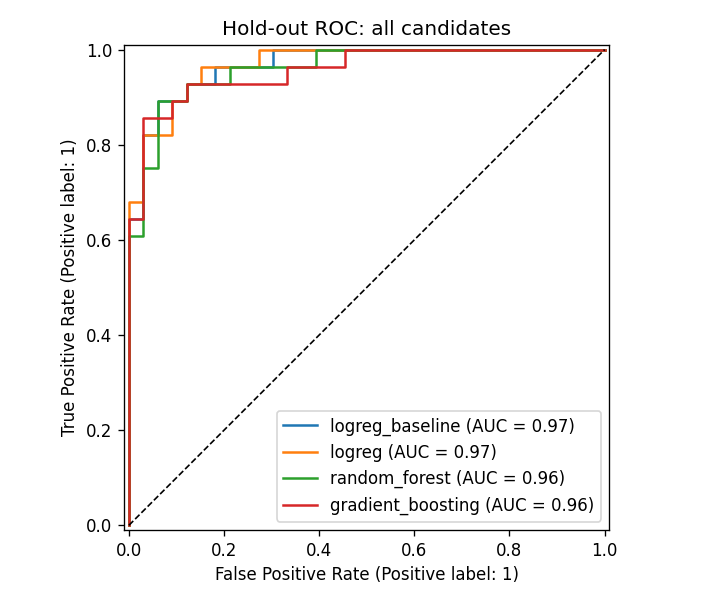

gradient_boosting_evaluation.png


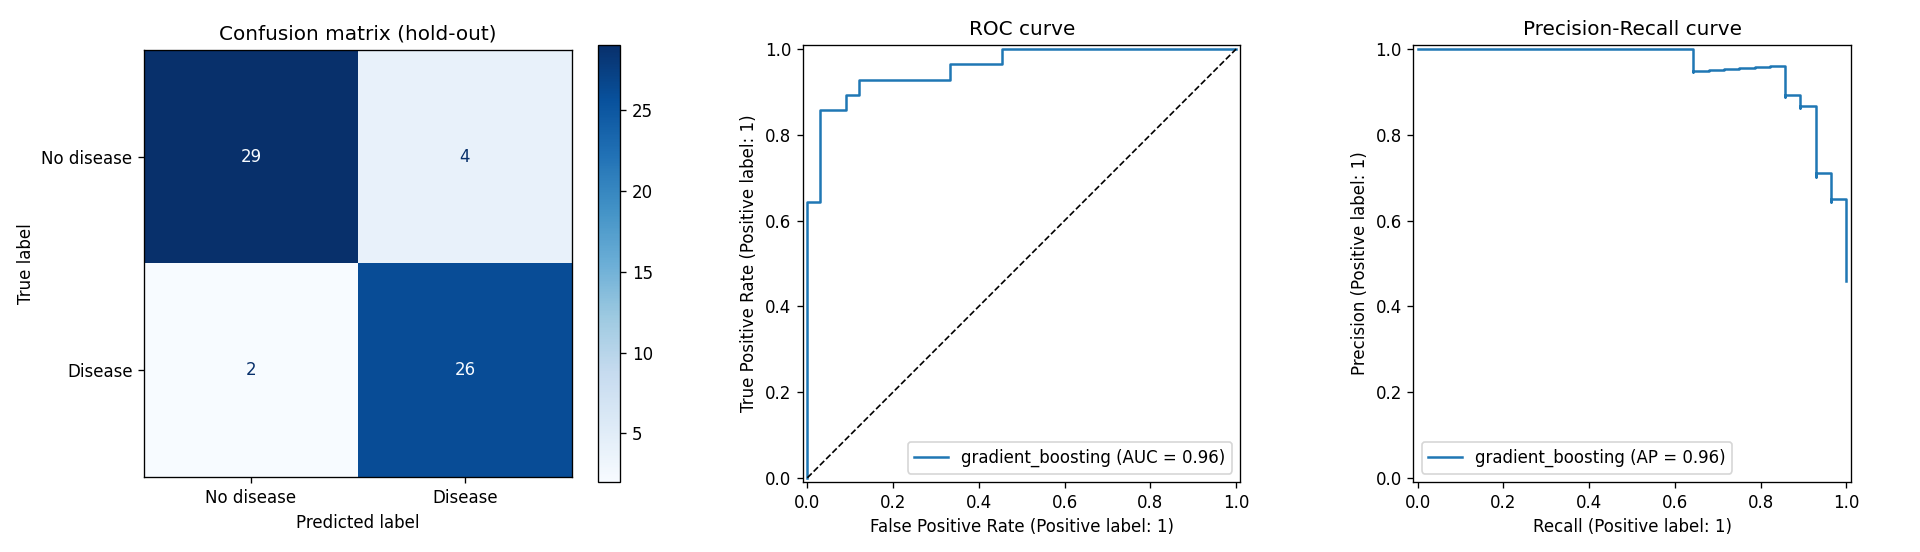

logreg_baseline_evaluation.png


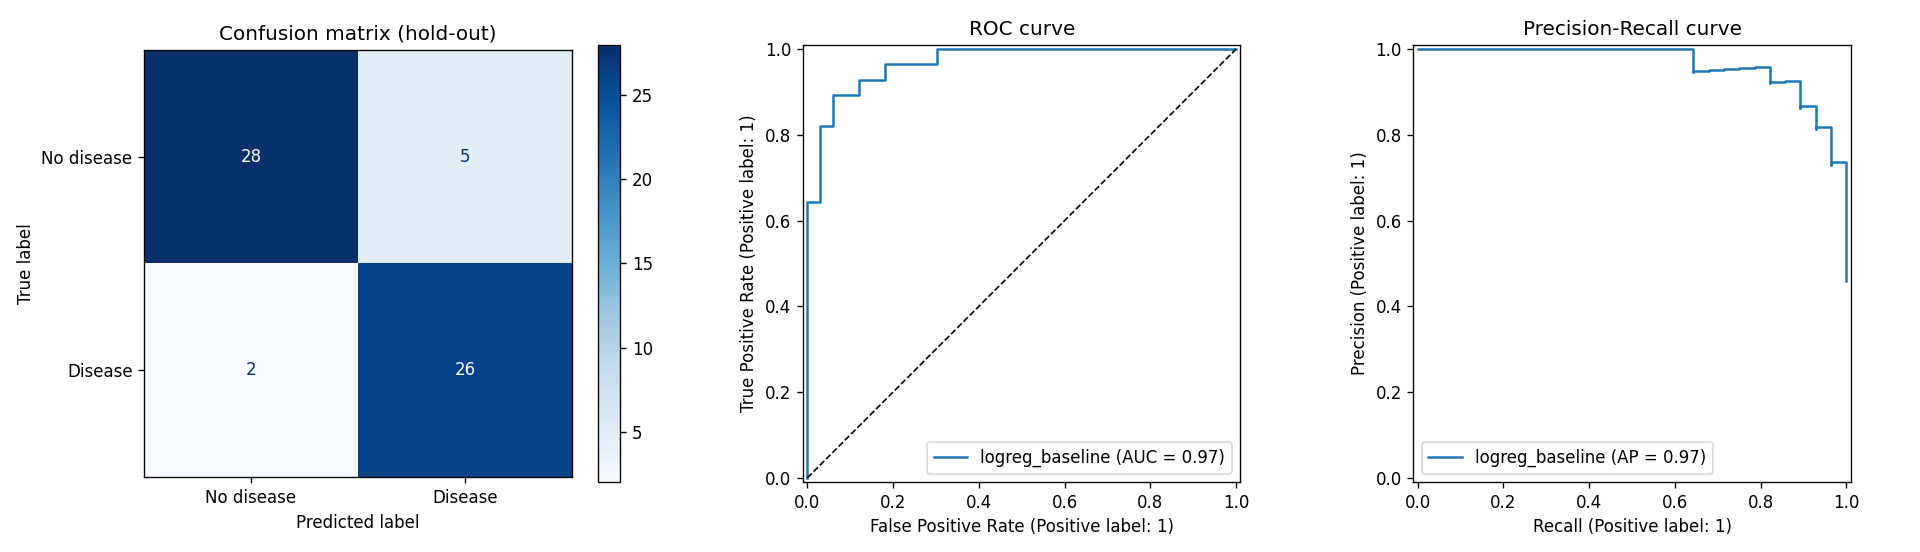

logreg_evaluation.png


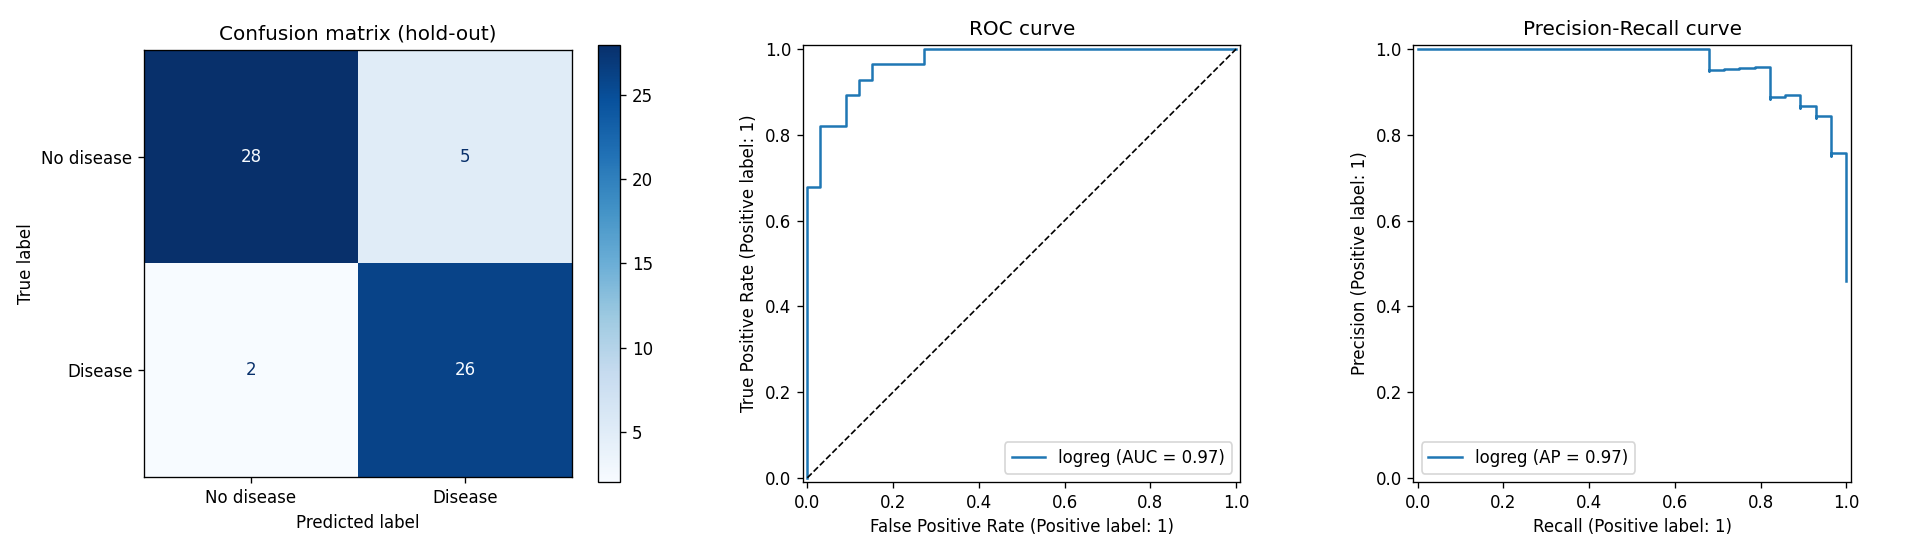

random_forest_evaluation.png


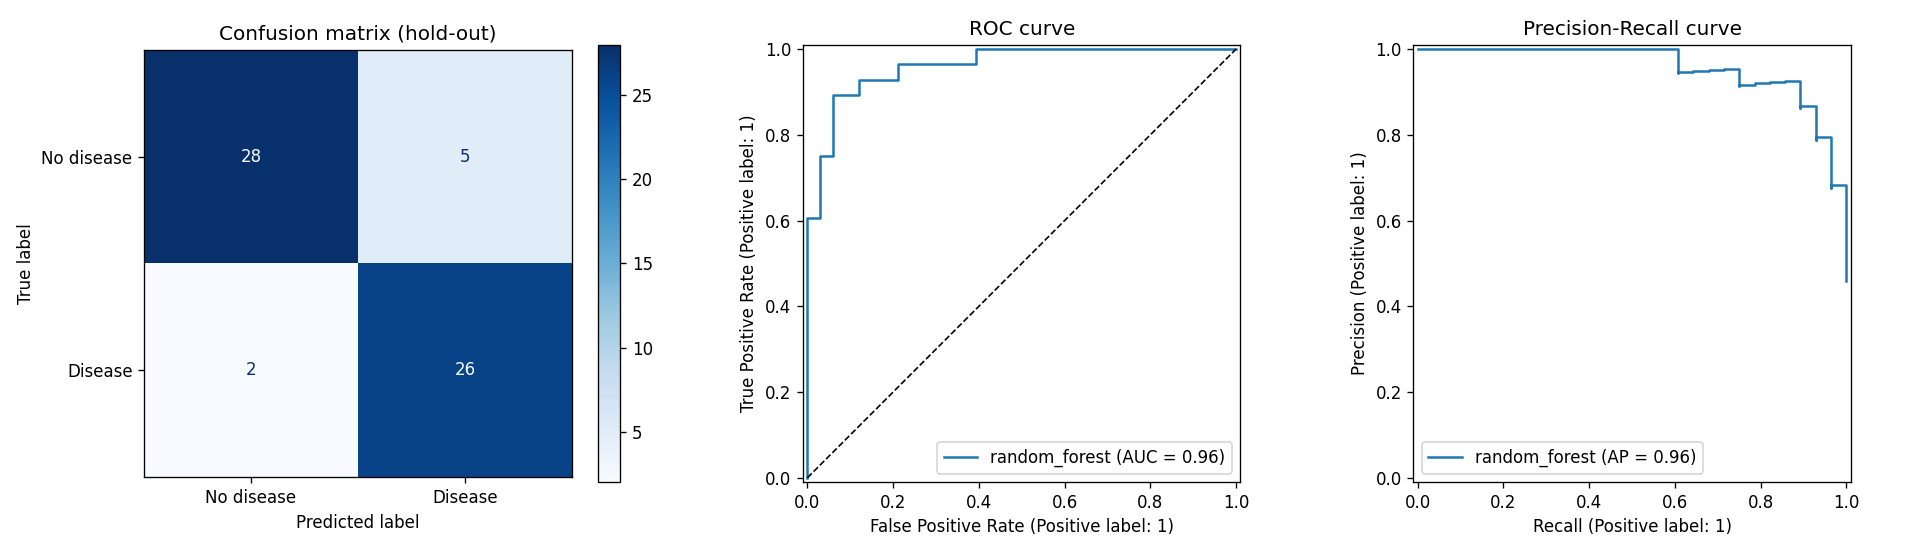

In [7]:
from IPython.display import Image, display
display(Image(filename="reports/figures/models/roc_all_models.png"))
for f in sorted((ROOT/"reports/figures/models").glob("*_evaluation.png")):
    print(f.name); display(Image(filename=str(f)))

## Model selection notes
Selection rule: highest mean 5-fold CV ROC-AUC on the training split (hold-out set only for final reporting). `logreg_baseline` (no engineered features) is an ablation to show whether feature engineering helps.

*Record your own interpretation here.*